# Demo: LLMs for EDA & Human-in-the-Loop Visualization

**Unit 4 · AI-Assisted Visualization · Lecture 3**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

This notebook walks through every topic of the lecture on **one synthetic dataset** (housing listings) plus a few small synthetic tables for the hypothesis, validation and case-study sections. It needs no internet and **no API key**.

> **About the "LLM" in this notebook.** To keep everything offline and deterministic, the "assistant" is a small **rule-based stand-in** (`mock_llm_*` functions). It plays the role an LLM plays in the lecture: it receives a *compact profile* of the data and turns it into language. The numbers always come from pandas/scipy code you can read. To use a real model, replace the body of `ask_llm()` in Section 3 with your provider's API call; nothing else changes.

| Section | Lecture topic |
|---|---|
| 1 | Why LLMs for EDA; the EDA loop |
| 2–3 | Data summarization using LLMs; compute first, then narrate |
| 4 | Automated EDA reports and reading their alerts |
| 5 | Defaults in automated reports: bin width and bandwidth |
| 6–7 | LLM-generated insights and narratives; decluttering and colour-linking |
| 8–10 | Automatic identification of trends, correlations and patterns |
| 11 | Scanning many pairs produces false patterns |
| 12 | LLM-generated hypotheses; Simpson's paradox |
| 13 | Data interpretation using natural language |
| 14–16 | Human-in-the-loop: validation, correction, interactive refinement, trust and controllability |
| 17 | Validation vs verification; division of responsibility |
| 18 | Measuring the AI's insights: precision, recall, F1 |
| 19–20 | End-to-end case study; designing AI outputs |

In [1]:
import copy, itertools, json, re, textwrap
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

## 1 · Why LLMs for EDA? The synthetic dataset

EDA is iterative (Tukey): look at the data from many angles before modelling. An LLM can **write the profiling code, summarize results, suggest next questions and draft hypotheses**. It cannot supply **domain knowledge, the real question behind the request, or responsibility for the conclusion**.

We build a synthetic table of **housing listings** with problems planted on purpose, so the automated tools have something to find: a right-skewed price, an identifier column, 31% missing ratings, near-duplicate listings, a rare category, a constant column and strongly correlated columns.

In [2]:
rng = np.random.default_rng(42)
N = 4000
cities = ["Bengaluru", "Mumbai", "Pune", "Hyderabad", "Chennai", "Delhi"]
rate = {"Bengaluru": 6500, "Mumbai": 14000, "Pune": 6000, "Hyderabad": 5800, "Chennai": 5500, "Delhi": 9500, "Goa": 8000}

city = rng.choice(cities, N, p=[.30, .22, .15, .15, .10, .08]).astype(object)
city[:3] = "Goa"                                                   # rare category on purpose
area = np.clip(rng.lognormal(np.log(1100), 0.38, N), 350, 6000).round(0)
bhk = np.clip(np.round(area / 520 + rng.normal(0, 0.45, N)), 1, 6).astype(int)
price = area * np.array([rate[c] for c in city]) / 1e5 * rng.lognormal(0, 0.22, N)
lux = rng.random(N) < 0.015
price[lux] *= rng.uniform(3, 6, lux.sum())                         # a few very expensive homes
age = np.where(rng.random(N) < 0.48, rng.normal(4, 2.2, N), rng.normal(17, 6, N)).clip(0, 40)   # dip near 10
dist = rng.gamma(2.0, 1.5, N).clip(0.2, 15)
rating = (4.4 - 0.15 * dist + rng.normal(0, 0.45, N)).clip(1, 5).round(1)
rating[rng.random(N) < 0.31] = np.nan                              # 31% missing
mon = np.arange(12)
w = 1 + 0.035 * mon + 0.08 * np.sin(mon / 12 * 2 * np.pi)
m = rng.choice(12, N, p=w / w.sum())
listed = pd.to_datetime(dict(year=2025, month=m + 1, day=rng.integers(1, 28, N)))

df = pd.DataFrame({
    "listing_id": [f"L{100000 + i}" for i in range(N)],
    "city": city, "area_sqft": area, "bhk": bhk, "price_lakh": price.round(1),
    "property_age_years": age.round(1), "distance_to_metro_km": dist.round(1),
    "furnishing": rng.choice(["Unfurnished", "Semi", "Furnished"], N, p=[.4, .4, .2]),
    "rating": rating, "listed_date": listed, "country": "India",
})
dups = df.sample(25, random_state=1).copy()                        # re-posted listings with new ids
dups["listing_id"] = [f"L{900000 + i}" for i in range(len(dups))]
df = pd.concat([df, dups], ignore_index=True)
print(df.shape)
df.head()

(4025, 11)


,listing_id,city,area_sqft,bhk,price_lakh,property_age_years,distance_to_metro_km,furnishing,rating,listed_date,country
0,L100000,Goa,741.0,1,56.2,11.4,3.9,Unfurnished,3.5,2025-01-25,India
1,L100001,Goa,623.0,1,47.1,5.0,4.7,Semi,NaN,2025-07-12,India
2,L100002,Goa,1839.0,4,103.6,22.8,4.2,Furnished,NaN,2025-10-08,India
3,L100003,Hyderabad,2762.0,5,157.6,15.4,2.6,Furnished,4.2,2025-09-26,India
4,L100004,Bengaluru,918.0,2,37.9,27.4,1.2,Unfurnished,3.9,2025-07-14,India


## 2 · Data summarization: what EDA looks for

Each EDA question has a **statistic** an AI computes and a **chart** that confirms it (Wilke).

| EDA question | Statistic | Chart |
|---|---|---|
| How is one variable distributed? | mean, median, SD, skew, quantiles | Histogram / density |
| How do groups differ? | group means, IQR, counts | Boxplot / violin |
| How are two variables related? | Pearson r, Spearman ρ | Scatter plot |
| Which of many pairs matter? | correlation matrix | Correlogram |
| Is the data trustworthy? | % missing, duplicates, outliers | Bar of missingness |

       price_lakh  area_sqft  rating
count      4000.0     4000.0  2786.0
mean        105.2     1182.4     3.9
std          94.4      467.7     0.5
min          15.3      350.0     1.9
25%          57.2      855.0     3.6
50%          81.1     1091.0     3.9
75%         125.0     1415.0     4.3
max        2496.7     4087.0     5.0

price skew: 8.43 | mean: 105.2 | median: 81.1
Pearson r (area, price): 0.46 | Spearman: 0.64


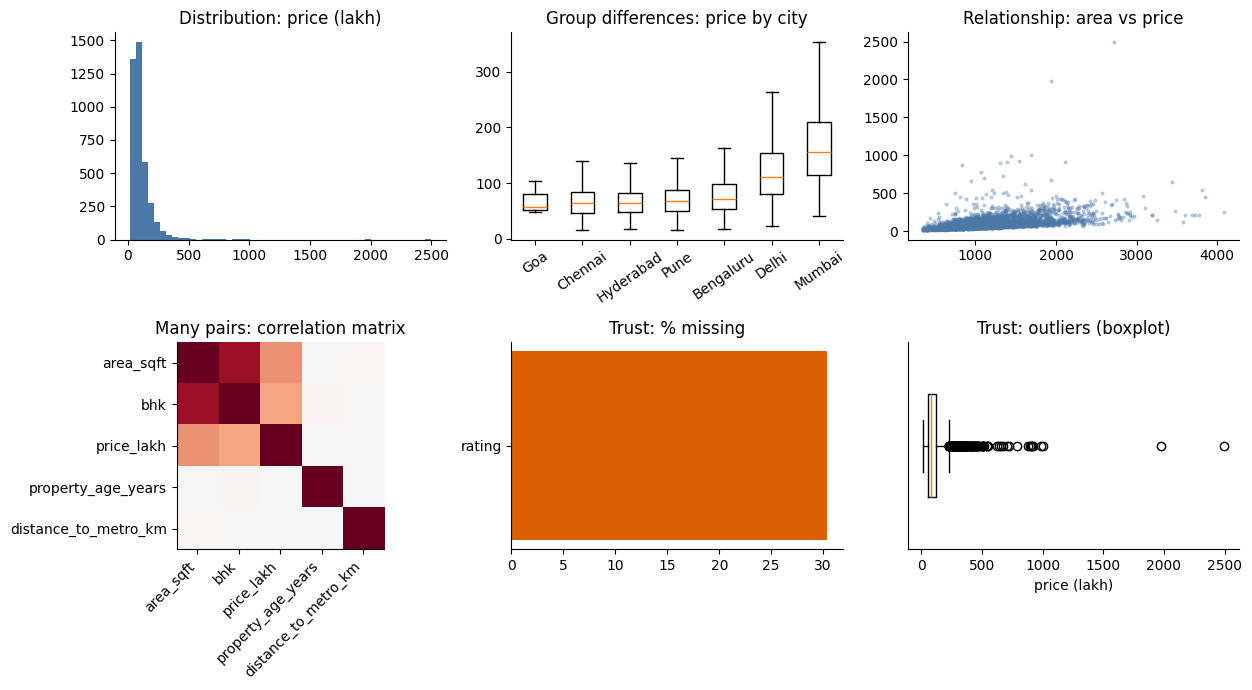

In [3]:
d = df.drop_duplicates(subset=[c for c in df.columns if c != "listing_id"])
num = ["area_sqft", "bhk", "price_lakh", "property_age_years", "distance_to_metro_km"]

print(d[["price_lakh", "area_sqft", "rating"]].describe().round(1))
print("\nprice skew:", round(d.price_lakh.skew(), 2), "| mean:", round(d.price_lakh.mean(), 1), "| median:", round(d.price_lakh.median(), 1))
print("Pearson r (area, price):", round(d.area_sqft.corr(d.price_lakh), 2), "| Spearman:", round(d.area_sqft.corr(d.price_lakh, method="spearman"), 2))

fig, ax = plt.subplots(2, 3, figsize=(13, 7))
ax[0, 0].hist(d.price_lakh, bins=50, color=BLUE); ax[0, 0].set_title("Distribution: price (lakh)")
order = d.groupby("city").price_lakh.median().sort_values().index
ax[0, 1].boxplot([d.loc[d.city == c, "price_lakh"] for c in order], showfliers=False)
ax[0, 1].set_xticks(range(1, len(order) + 1)); ax[0, 1].set_xticklabels(order, rotation=35)
ax[0, 1].set_title("Group differences: price by city")
ax[0, 2].scatter(d.area_sqft, d.price_lakh, s=4, alpha=.3, color=BLUE); ax[0, 2].set_title("Relationship: area vs price")
cm = d[num].corr()
im = ax[1, 0].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1, 0].set_xticks(range(len(num))); ax[1, 0].set_xticklabels(num, rotation=45, ha="right")
ax[1, 0].set_yticks(range(len(num))); ax[1, 0].set_yticklabels(num); ax[1, 0].set_title("Many pairs: correlation matrix")
miss = d.isna().mean().mul(100).loc[lambda s: s > 0]
ax[1, 1].barh(miss.index, miss.values, color=ACCENT, height=0.35); ax[1, 1].set_title("Trust: % missing")
ax[1, 2].boxplot(d.price_lakh, vert=False, widths=0.5); ax[1, 2].set_yticks([]); ax[1, 2].set_xlabel("price (lakh)")
ax[1, 2].set_title("Trust: outliers (boxplot)")
plt.tight_layout(); plt.show()

## 3 · How it works: compute first, then narrate

1. A **profiler** (pandas, ydata-profiling) computes exact statistics.
2. The LLM receives **only this compact profile** plus a few sample rows.
3. The LLM turns it into a readable summary, flags issues and proposes next questions.

In [4]:
def build_profile(d, id_cols=("listing_id",), top_corr=3):
    prof = {"rows": int(len(d)), "columns": int(d.shape[1])}
    detail = {}
    for c in d.columns:
        s = d[c]
        info = {"missing_pct": round(float(s.isna().mean() * 100), 1)}
        if c in id_cols or s.nunique() == len(s):
            info.update(type="identifier", unique_pct=round(s.nunique() / len(s) * 100, 1))
        elif pd.api.types.is_datetime64_any_dtype(s):
            info.update(type="date", min=str(s.min().date()), max=str(s.max().date()))
        elif pd.api.types.is_numeric_dtype(s):
            info.update(type="float", mean=round(float(s.mean()), 1), median=round(float(s.median()), 1), skew=round(float(s.skew()), 2))
        else:
            vc = s.value_counts()
            info.update(type="category", unique=int(s.nunique()), top=str(vc.index[0]), top_share_pct=round(vc.iloc[0] / len(s) * 100, 1))
        detail[c] = info
    prof["columns_detail"] = detail
    numd = d.select_dtypes("number").drop(columns=[c for c in id_cols if c in d], errors="ignore")
    cm = numd.corr()
    pairs = [(a, b, cm.loc[a, b]) for a, b in itertools.combinations(cm.columns, 2)]
    pairs.sort(key=lambda t: -abs(t[2]))
    prof["top_correlations"] = {f"{a}~{b}": round(float(r), 2) for a, b, r in pairs[:top_corr]}
    prof["duplicate_rows_ignoring_id"] = int(d.drop(columns=list(id_cols)).duplicated().sum())
    return prof

profile = build_profile(df)
print(json.dumps(profile, indent=1)[:1800], "...")

{
 "rows": 4025,
 "columns": 11,
 "columns_detail": {
  "listing_id": {
   "missing_pct": 0.0,
   "type": "identifier",
   "unique_pct": 100.0
  },
  "city": {
   "missing_pct": 0.0,
   "type": "category",
   "unique": 7,
   "top": "Bengaluru",
   "top_share_pct": 30.5
  },
  "area_sqft": {
   "missing_pct": 0.0,
   "type": "float",
   "mean": 1182.2,
   "median": 1091.0,
   "skew": 1.26
  },
  "bhk": {
   "missing_pct": 0.0,
   "type": "float",
   "mean": 2.3,
   "median": 2.0,
   "skew": 0.81
  },
  "price_lakh": {
   "missing_pct": 0.0,
   "type": "float",
   "mean": 105.2,
   "median": 81.1,
   "skew": 8.39
  },
  "property_age_years": {
   "missing_pct": 0.0,
   "type": "float",
   "mean": 10.8,
   "median": 8.2,
   "skew": 0.57
  },
  "distance_to_metro_km": {
   "missing_pct": 0.0,
   "type": "float",
   "mean": 3.0,
   "median": 2.5,
   "skew": 1.43
  },
  "furnishing": {
   "missing_pct": 0.0,
   "type": "category",
   "unique": 3,
   "top": "Unfurnished",
   "top_share_pct": 

In [5]:
def mock_llm_summarize(p):
    # Rule-based stand-in for an LLM: turns a profile into sentences, each tagged by how much to trust it.
    out, cd = [], p["columns_detail"]
    cats = {c: i for c, i in cd.items() if i["type"] == "category" and i["unique"] > 1}
    out.append((f"The dataset has {p['rows']:,} rows and {p['columns']} columns.", "restates profile"))
    if "city" in cd:
        i = cd["city"]
        out.append((f"Listings span {i['unique']} cities, led by {i['top']} ({i['top_share_pct']}%).", "restates profile"))
    for c, i in cd.items():
        if i["type"] == "float" and i["skew"] > 1:
            out.append((f"{c} is right-skewed (skew {i['skew']}): the mean ({i['mean']}) is well above the median ({i['median']}), "
                        f"so a few very high values pull the average up.", "correct reading of skew"))
        if i["missing_pct"] > 20:
            out.append((f"{i['missing_pct']}% of {c} values are missing, so summaries of {c} may be biased.", "restates profile"))
        if i["type"] == "identifier":
            out.append((f"{c} is an identifier and should not be analysed as a number.", "correct reading of names/patterns"))
        if i["type"] == "category" and i["unique"] == 1:
            out.append((f"{c} has a single value and carries no information.", "correct reading of names/patterns"))
    if p["duplicate_rows_ignoring_id"]:
        out.append((f"{p['duplicate_rows_ignoring_id']} rows repeat another row apart from the id; they may be re-posted listings.", "hypothesis: verify"))
    for pair, r in p["top_correlations"].items():
        a, b = pair.split("~")
        out.append((f"{a} and {b} move together (r = {r}), possibly because they measure overlapping things.", "hypothesis: verify"))
    return out

ICON = {"restates profile": "✔", "correct reading of skew": "✔", "correct reading of names/patterns": "✔", "hypothesis: verify": "⚠"}
for sentence, tag in mock_llm_summarize(profile):
    print(f"{ICON[tag]} {sentence}   [{tag}]")

✔ The dataset has 4,025 rows and 11 columns.   [restates profile]
✔ Listings span 7 cities, led by Bengaluru (30.5%).   [restates profile]
✔ listing_id is an identifier and should not be analysed as a number.   [correct reading of names/patterns]
✔ area_sqft is right-skewed (skew 1.26): the mean (1182.2) is well above the median (1091.0), so a few very high values pull the average up.   [correct reading of skew]
✔ price_lakh is right-skewed (skew 8.39): the mean (105.2) is well above the median (81.1), so a few very high values pull the average up.   [correct reading of skew]
✔ distance_to_metro_km is right-skewed (skew 1.43): the mean (3.0) is well above the median (2.5), so a few very high values pull the average up.   [correct reading of skew]
✔ 30.4% of rating values are missing, so summaries of rating may be biased.   [restates profile]
✔ country has a single value and carries no information.   [correct reading of names/patterns]
⚠ 25 rows repeat another row apart from the id; the

In [6]:
def ask_llm(prompt: str) -> str:
    # Replace this body with a real API call (any provider). The notebook does not need it.
    return "(no model attached: using mock_llm_summarize above)"

prompt = ("You are an EDA assistant. Use ONLY the profile below. Do not compute new numbers. "
          "Summarize it, flag data-quality issues, and label any guess as a hypothesis.\n\nPROFILE:\n" + json.dumps(profile))
raw_chars, prof_chars = len(df.to_csv(index=False)), len(prompt)
print(f"Raw table as text : {raw_chars:>9,} characters (~{raw_chars // 4:,} tokens)")
print(f"Prompt with profile: {prof_chars:>8,} characters (~{prof_chars // 4:,} tokens)  -> {raw_chars / prof_chars:.0f}x smaller, and only aggregates leave your machine.")

Raw table as text :   271,475 characters (~67,868 tokens)
Prompt with profile:    1,453 characters (~363 tokens)  -> 187x smaller, and only aggregates leave your machine.


**Why compute first, then narrate?** An LLM that has to *read* a large table cannot see it all and tends to approximate. Below, we **simulate** that: the "model" only sees the first 40 rows that fit its context window.

In [7]:
ordered = df.sort_values("listed_date")
seen = ordered.head(40)
rows = [
    ("Mean price (lakh)", seen.price_lakh.mean(), df.price_lakh.mean()),
    ("Median price (lakh)", seen.price_lakh.median(), df.price_lakh.median()),
    ("Share of Bengaluru listings (%)", (seen.city == "Bengaluru").mean() * 100, (df.city == "Bengaluru").mean() * 100),
    ("Missing ratings (%)", seen.rating.isna().mean() * 100, df.rating.isna().mean() * 100),
]
cmp = pd.DataFrame(rows, columns=["Statistic", "'LLM' reading 40 rows", "Code on all rows"]).round(1)
cmp["error %"] = ((cmp.iloc[:, 1] - cmp.iloc[:, 2]) / cmp.iloc[:, 2] * 100).round(0)
display(cmp)
print("Rule for this course: every number an AI states must come from code you can inspect.")

,Statistic,'LLM' reading 40 rows,Code on all rows,error %
0,Mean price (lakh),96.9,105.2,-8.0
1,Median price (lakh),75.0,81.1,-8.0
2,Share of Bengaluru listings (%),32.5,30.5,7.0
3,Missing ratings (%),25.0,30.4,-18.0


Rule for this course: every number an AI states must come from code you can inspect.


## 4 · Automated EDA reports

A report contains an **overview**, **per-variable** summaries, **interactions/correlations**, **missing values** and **alerts**. Tools: ydata-profiling, Sweetviz, D-Tale, AutoViz, LIDA, ChatGPT data analysis. Below is a small report generator that produces the same sections, so you can see what is behind the alerts.

In [8]:
try:
    import ydata_profiling                                         # optional; not needed for this demo
    print("ydata-profiling is installed: ProfileReport(df).to_notebook_iframe() would build the full report.")
except ImportError:
    print("ydata-profiling not installed; using our own mini report (same sections, fewer pages).")

def eda_report(d, id_cols=("listing_id",)):
    body = d.drop(columns=list(id_cols))
    overview = {"rows": len(d), "columns": d.shape[1], "missing_cells": int(d.isna().sum().sum()),
                "duplicate_rows": int(body.duplicated().sum()), "memory_kb": round(d.memory_usage(deep=True).sum() / 1024)}
    variables = pd.DataFrame({"dtype": d.dtypes.astype(str), "missing_%": d.isna().mean().mul(100).round(1), "unique": d.nunique()})
    numd = d.select_dtypes("number")
    corr = numd.corr()
    alerts = []
    for c in numd:
        sk = numd[c].skew()
        if abs(sk) > 1:
            alerts.append(("High skew", c, f"skew = {sk:.2f}", "Histogram / density (Ch 7)"))
    for a, b in itertools.combinations(corr.columns, 2):
        if abs(corr.loc[a, b]) > 0.8:
            alerts.append(("High correlation", f"{a} ~ {b}", f"r = {corr.loc[a, b]:.2f}", "Scatter plot (Ch 12)"))
    for c in d:
        mp = d[c].isna().mean() * 100
        if mp > 20:
            alerts.append(("Many missing", c, f"{mp:.0f}% missing", "Missingness bar by group"))
        if c in id_cols or d[c].nunique() == len(d):
            alerts.append(("Unique values", c, "100% unique: identifier", "Check the data type (Ch 2)"))
        if d[c].nunique() == 1:
            alerts.append(("Constant", c, "one value only", "Drop the column"))
    vc = d["city"].value_counts()
    for k, v in vc[vc < 5].items():
        alerts.append(("Rare categories", f"city = {k}", f"only {v} rows", "Bar of counts per group"))
    if overview["duplicate_rows"]:
        alerts.append(("Duplicates", "(all columns except id)", f"{overview['duplicate_rows']} repeated rows", "Count of duplicates by source"))
    return overview, variables, corr, alerts

overview, variables, corr, alerts = eda_report(df)
print("OVERVIEW", overview)
display(variables)
print("\nALERTS (where to look)")
display(pd.DataFrame(alerts, columns=["Alert", "Where", "Detail", "Verify with"]))

ydata-profiling not installed; using our own mini report (same sections, fewer pages).
OVERVIEW {'rows': 4025, 'columns': 11, 'missing_cells': 1225, 'duplicate_rows': 25, 'memory_kb': 1096}


,dtype,missing_%,unique
listing_id,object,0.0,4025
city,object,0.0,7
area_sqft,float64,0.0,1531
bhk,int64,0.0,6
price_lakh,float64,0.0,1669
property_age_years,float64,0.0,319
distance_to_metro_km,float64,0.0,124
furnishing,object,0.0,3
rating,float64,30.4,32
listed_date,datetime64[ns],0.0,324



ALERTS (where to look)


,Alert,Where,Detail,Verify with
0,High skew,area_sqft,skew = 1.26,Histogram / density (Ch 7)
1,High skew,price_lakh,skew = 8.39,Histogram / density (Ch 7)
2,High skew,distance_to_metro_km,skew = 1.43,Histogram / density (Ch 7)
3,High correlation,area_sqft ~ bhk,r = 0.85,Scatter plot (Ch 12)
4,Unique values,listing_id,100% unique: identifier,Check the data type (Ch 2)
5,Many missing,rating,30% missing,Missingness bar by group
6,Constant,country,one value only,Drop the column
7,Rare categories,city = Goa,only 3 rows,Bar of counts per group
8,Duplicates,(all columns except id),25 repeated rows,Count of duplicates by source


### Reading the alerts: from warning to verification chart
> **An alert tells you where to look; the chart tells you what is true.**

| Alert | Risk if ignored | Verify with |
|---|---|---|
| High skew (price) | mean misleads; LLM reports 'average' | histogram / density |
| High correlation (area ~ bhk) | double counting in models | scatter plot |
| Many missing (rating) | biased summaries | missingness bar by group |
| Unique values (listing_id) | meaningless 'average ID' | check the data type |
| Rare categories, Duplicates | unstable group means; inflated counts | counts per group |

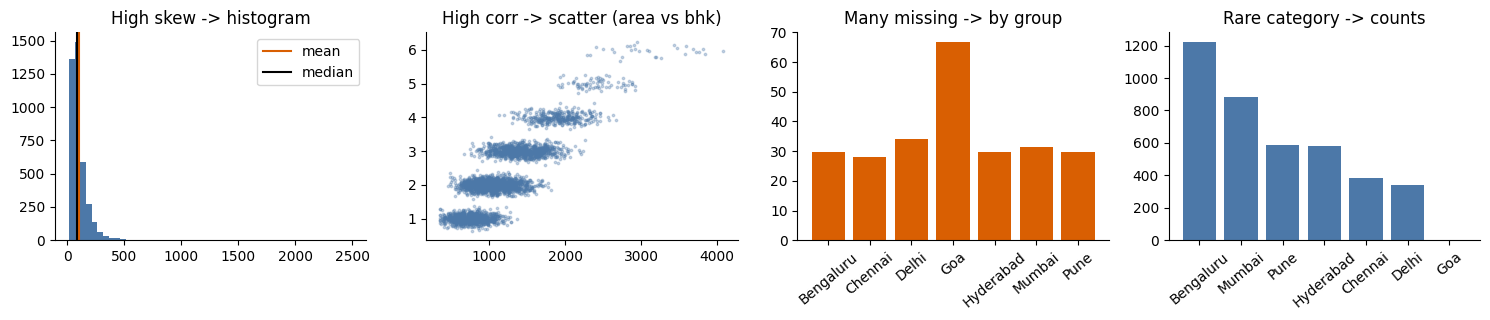

Mean of listing_id is meaningless; dtype check -> object (an identifier, not a measure)


In [9]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.3))
ax[0].hist(d.price_lakh, bins=50, color=BLUE); ax[0].axvline(d.price_lakh.mean(), color=ACCENT, label="mean"); ax[0].axvline(d.price_lakh.median(), color="k", label="median")
ax[0].legend(); ax[0].set_title("High skew -> histogram")
j = rng.normal(0, .12, len(d)); ax[1].scatter(d.area_sqft, d.bhk + j, s=3, alpha=.3, color=BLUE); ax[1].set_title("High corr -> scatter (area vs bhk)")
mb = d.groupby("city").rating.apply(lambda s: s.isna().mean() * 100); ax[2].bar(mb.index, mb.values, color=ACCENT); ax[2].tick_params(axis="x", rotation=40); ax[2].set_title("Many missing -> by group")
cnt = d.city.value_counts(); ax[3].bar(cnt.index, cnt.values, color=[ACCENT if v < 5 else BLUE for v in cnt.values]); ax[3].tick_params(axis="x", rotation=40); ax[3].set_title("Rare category -> counts")
plt.tight_layout(); plt.show()
print("Mean of listing_id is meaningless; dtype check ->", df["listing_id"].dtype, "(an identifier, not a measure)")

## 5 · Automated reports inherit default choices

### 5a · Bin width (Wilke Ch 7)
A histogram's look depends on bin width, and programs pick a default. **Too small:** peaky and busy. **Too large:** small features disappear. An LLM reading a 1-year histogram may report a "multimodal" pattern that is only noise. Our `property_age_years` has a real dip near 10 years: watch which bin widths keep it visible.

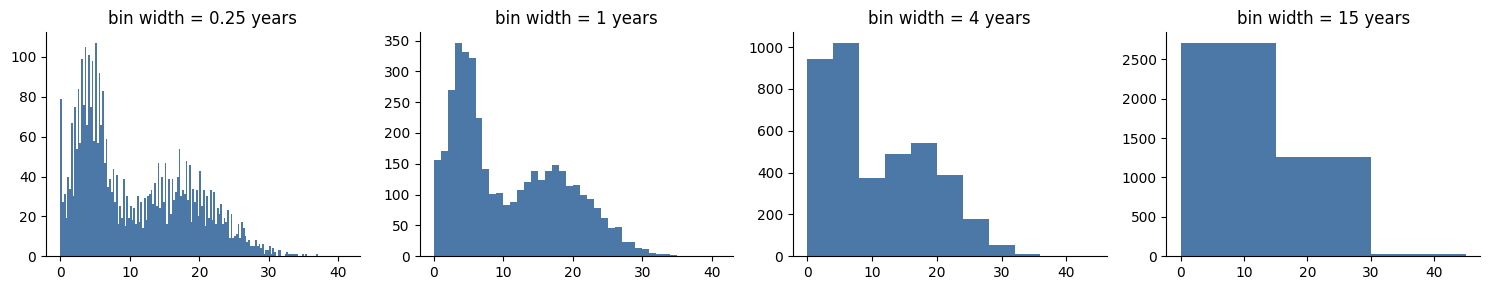

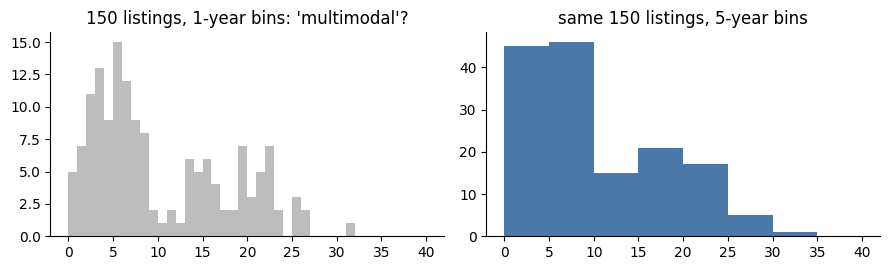

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a, w_ in zip(ax, [0.25, 1, 4, 15]):
    a.hist(d.property_age_years, bins=np.arange(0, 41 + w_, w_), color=BLUE); a.set_title(f"bin width = {w_} years")
plt.tight_layout(); plt.show()
sample = d.property_age_years.sample(150, random_state=3)
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
ax[0].hist(sample, bins=np.arange(0, 41, 1), color=GREY); ax[0].set_title("150 listings, 1-year bins: 'multimodal'?")
ax[1].hist(sample, bins=np.arange(0, 45, 5), color=BLUE); ax[1].set_title("same 150 listings, 5-year bins")
plt.tight_layout(); plt.show()

### 5b · Density plots: bandwidth and impossible values
Small bandwidth gives a spiky curve; large bandwidth over-smooths. And, as Wilke warns, *always verify that your density estimate does not predict the existence of nonsensical data values.*

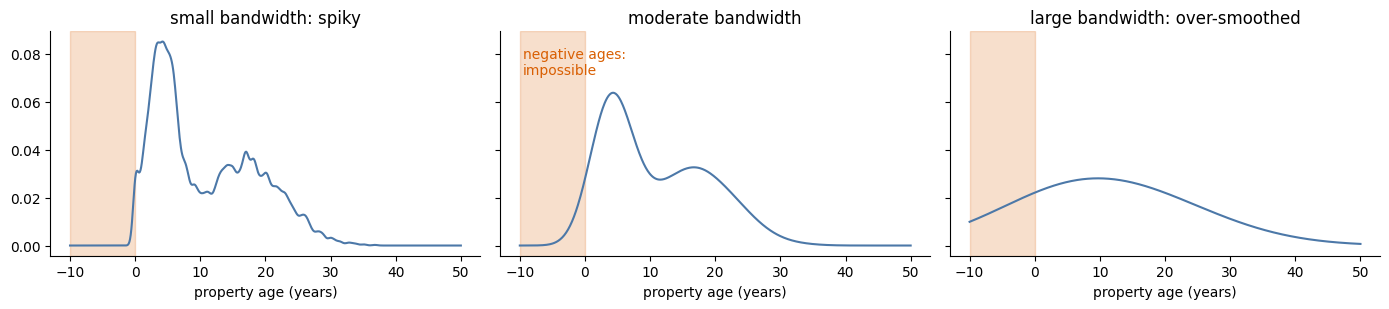

Density mass the smooth curve assigns to NEGATIVE ages: 4.9%  -> an automated report would not warn you.


In [11]:
x = np.linspace(-10, 50, 600)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for a, (bw, lab) in zip(ax, [(0.05, "small bandwidth: spiky"), (0.3, "moderate bandwidth"), (1.5, "large bandwidth: over-smoothed")]):
    a.plot(x, stats.gaussian_kde(d.property_age_years, bw_method=bw)(x), color=BLUE)
    a.axvspan(-10, 0, color=ACCENT, alpha=.2); a.set_title(lab); a.set_xlabel("property age (years)")
ax[1].text(-9.5, ax[1].get_ylim()[1] * .8, "negative ages:\nimpossible", color=ACCENT)
plt.tight_layout(); plt.show()
kde = stats.gaussian_kde(d.property_age_years, bw_method=0.3)
print(f"Density mass the smooth curve assigns to NEGATIVE ages: {kde.integrate_box_1d(-50, 0):.1%}  -> an automated report would not warn you.")

## 6 · LLM-generated insights: what counts as an insight?

| Type | Template | Typical chart |
|---|---|---|
| Trend | measure rose/fell X% over period | line |
| Extreme | item has the highest/lowest measure | sorted bar |
| Outlier | item is unusually high/low | boxplot / scatter |
| Comparison | A is X% higher than B | grouped bar |
| Correlation | x and y move together (r = …) | scatter |
| Composition | part makes up X% of whole | stacked bar |
| Distribution | measure is skewed / bimodal | histogram |

### From insights to a narrative
**Extract typed facts → score by statistical strength and relevance to the question → remove near-duplicates → order (context, main finding, supporting detail) → narrate, pairing each claim with a chart highlight.**

In [12]:
@dataclass
class Insight:
    kind: str
    text: str
    strength: float          # 0-1 statistical strength
    relevance: float         # 0-1 relevance to the user's question
    columns: tuple
    code: str
    n: int
    @property
    def score(self): return round(self.strength * self.relevance, 3)

def extract_insights(d, focus="price_lakh"):
    out = []
    rel = lambda cols: 1.0 if focus in cols else 0.6
    monthly = d.groupby(d.listed_date.dt.month).size()
    tau, p = stats.kendalltau(monthly.index, monthly.values)
    chg = (monthly.iloc[-1] / monthly.iloc[0] - 1) * 100
    out.append(Insight("Trend", f"Monthly listings rose {chg:.0f}% from January to December.", abs(tau), rel(("listed_date",)), ("listed_date",),
                       "d.groupby(d.listed_date.dt.month).size(); kendalltau", len(d)))
    g = d.groupby("city").price_lakh.agg(["median", "size"])
    med = g[g["size"] >= 30]["median"].sort_values()                 # ignore groups with < 30 rows (unstable medians)
    out.append(Insight("Extreme", f"{med.index[-1]} has the highest median price (₹{med.iloc[-1]:.0f} lakh), {med.iloc[-1] / med.iloc[0]:.1f}x {med.index[0]}.",
                       min(1, np.log(med.iloc[-1] / med.iloc[0]) / np.log(4)), rel((focus,)), ("city", focus), "d.groupby('city').price_lakh.median()", len(d)))
    z = (np.log(d.price_lakh) - np.log(d.price_lakh).mean()) / np.log(d.price_lakh).std()
    top = d.loc[z.idxmax()]
    cm_ = d[d.city == top.city].price_lakh.median()
    out.append(Insight("Outlier", f"One {top.city} listing at ₹{top.price_lakh:.0f} lakh is {top.price_lakh / cm_:.1f}x its city median.",
                       min(1, z.max() / 10), rel((focus,)), ("city", focus), "z-score of log(price)", len(d)))
    a, b = med.index[-1], "Pune"
    ratio = med.loc[a] / med.loc[b]
    out.append(Insight("Comparison", f"{a} prices are {100 * (ratio - 1):.0f}% higher than {b}.", min(1, np.log(ratio) / np.log(4)), rel((focus,)), ("city", focus),
                       "median price ratio", len(d)))
    numd = d[["area_sqft", "bhk", "price_lakh", "property_age_years", "distance_to_metro_km"]]
    for x1, y1 in itertools.combinations(numd.columns, 2):
        r = numd[x1].corr(numd[y1])
        if abs(r) > 0.4:
            out.append(Insight("Correlation", f"{x1} and {y1} move together (r = {r:.2f}).", abs(r), rel((x1, y1)), (x1, y1), f"Pearson({x1}, {y1})", len(d)))
    share = (d.bhk == 2).mean()
    out.append(Insight("Composition", f"2BHK homes make up {share:.0%} of listings.", 0.5, 0.6, ("bhk",), "(d.bhk == 2).mean()", len(d)))
    out.append(Insight("Distribution", f"Price is right-skewed (skew {d.price_lakh.skew():.1f}); the median is more typical than the mean.",
                       min(1, d.price_lakh.skew() / 4), rel((focus,)), (focus,), "scipy skew", len(d)))
    return out

def dedupe(insights):
    keep = []
    for ins in sorted(insights, key=lambda i: -i.score):
        if any(k.kind == ins.kind and set(k.columns) & set(ins.columns) for k in keep):
            continue                                        # near-duplicate: same kind, shares a column with a stronger one
        keep.append(ins)
    return keep

raw = extract_insights(d)
kept = dedupe(raw)
display(pd.DataFrame([(i.kind, i.text, i.score) for i in sorted(raw, key=lambda i: -i.score)], columns=["type", "insight", "score"]).assign(
    kept=lambda t: t["insight"].isin([k.text for k in kept])))

,type,insight,score,kept
0,Distribution,Price is right-skewed (skew 8.4); the median i...,1.000,True
1,Extreme,Mumbai has the highest median price (₹155 lakh...,0.646,True
2,Comparison,Mumbai prices are 129% higher than Pune.,0.598,True
3,Outlier,One Mumbai listing at ₹2497 lakh is 16.1x its ...,0.564,True
4,Correlation,area_sqft and bhk move together (r = 0.85).,0.513,True
5,Correlation,area_sqft and price_lakh move together (r = 0....,0.459,False
6,Trend,Monthly listings rose 33% from January to Dece...,0.327,True
7,Composition,2BHK homes make up 43% of listings.,0.300,True


In [13]:
def narrate(kept):
    context = [i for i in kept if i.kind in ("Composition", "Distribution")]
    ranked = [i for i in kept if i not in context]
    main, support = ranked[0], ranked[1:4]
    lines = ["Context: " + " ".join(i.text for i in context),
             "Main finding: " + main.text,
             "Supporting detail: " + " ".join(i.text for i in support)]
    return lines, main, support

lines, main, support = narrate(kept)
print("\n".join(textwrap.fill(l, 110) for l in lines))

Context: Price is right-skewed (skew 8.4); the median is more typical than the mean. 2BHK homes make up 43% of
listings.
Main finding: Mumbai has the highest median price (₹155 lakh), 2.4x Chennai.
Supporting detail: Mumbai prices are 129% higher than Pune. One Mumbai listing at ₹2497 lakh is 16.1x its city
median. area_sqft and bhk move together (r = 0.85).


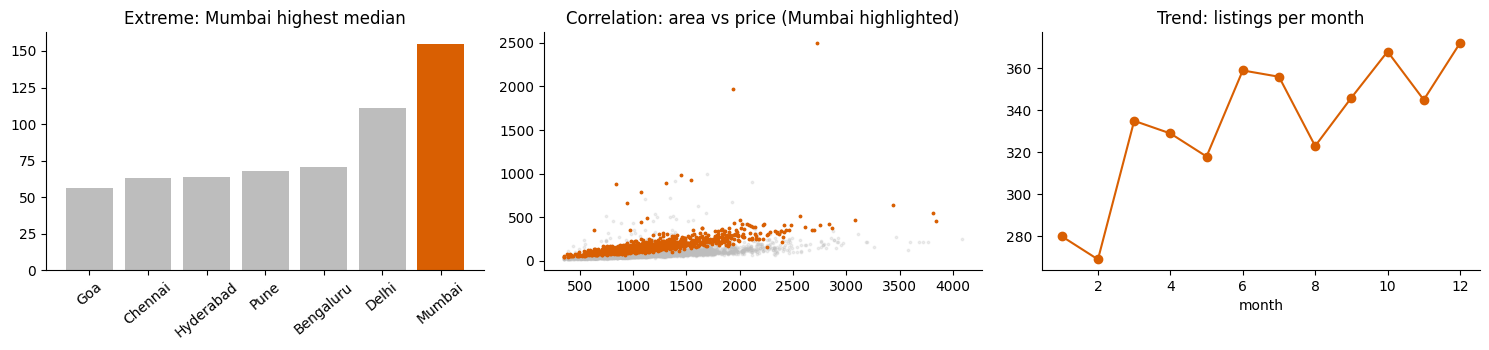

In [14]:
# Every claim is paired with a chart highlight, so a reader can find (and check) the sentence in the picture.
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
med = d.groupby("city").price_lakh.median().sort_values()
ax[0].bar(med.index, med.values, color=[ACCENT if c == med.index[-1] else GREY for c in med.index]); ax[0].set_title("Extreme: " + med.index[-1] + " highest median"); ax[0].tick_params(axis="x", rotation=40)
ax[1].scatter(d.area_sqft, d.price_lakh, s=3, alpha=.25, color=GREY); hi = d[d.city == "Mumbai"]; ax[1].scatter(hi.area_sqft, hi.price_lakh, s=3, color=ACCENT); ax[1].set_title("Correlation: area vs price (Mumbai highlighted)")
mo = d.groupby(d.listed_date.dt.month).size(); ax[2].plot(mo.index, mo.values, color=ACCENT, marker="o"); ax[2].set_title("Trend: listings per month"); ax[2].set_xlabel("month")
plt.tight_layout(); plt.show()

## 7 · AI charts need decluttering and colour-linking (Knaflic Ch 3–4)

**Declutter:** remove border and gridlines → grey the context → label directly → title with the takeaway.
**Link words to emphasis:** one or two accent colours; match the colour of a phrase to the data it describes; test where the eye goes first.

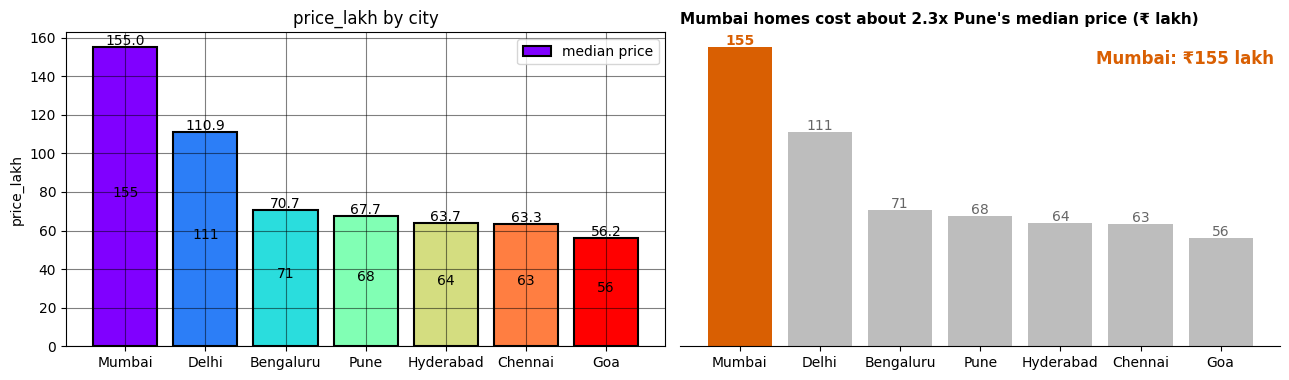

In [15]:
med = d.groupby("city").price_lakh.median().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))

# BEFORE: the kind of default chart an automated tool produces
a = ax[0]; cols = plt.cm.rainbow(np.linspace(0, 1, len(med)))
a.bar(med.index, med.values, color=cols, edgecolor="black", linewidth=1.5, label="median price"); a.grid(True, color="k", alpha=.5)
for s in a.spines.values(): s.set_visible(True)
for x_, v in zip(med.index, med.values): a.text(x_, v / 2, f"{v:.0f}", ha="center"); a.text(x_, v + 1, f"{v:.1f}", ha="center")
a.set_title("price_lakh by city"); a.legend(); a.set_ylabel("price_lakh")

# AFTER: grey context, one accent, direct labels, takeaway title, a phrase in the chart's colour
a = ax[1]; top = med.index[0]
a.bar(med.index, med.values, color=[ACCENT if c == top else GREY for c in med.index])
a.set_yticks([]); a.spines["left"].set_visible(False)
for x_, v in zip(med.index, med.values): a.text(x_, v + 1, f"{v:.0f}", ha="center", color=ACCENT if x_ == top else "#666", fontweight="bold" if x_ == top else None)
a.set_title(f"{top} homes cost about {med.iloc[0] / med.loc['Pune']:.1f}x Pune's median price (₹ lakh)", loc="left", fontweight="bold", fontsize=11)
a.text(0.99, 0.9, f"{top}: ₹{med.iloc[0]:.0f} lakh", transform=a.transAxes, ha="right", color=ACCENT, fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

## 8 · Automatic identification of trends

**Smooth → fit → test → describe.**
1. *Smooth* with a moving average or LOESS (removes noise and seasonality).
2. *Fit* a linear regression slope for direction and size.
3. *Test* whether the slope is distinguishable from zero (Mann–Kendall; here Kendall's τ against time).
4. *Describe*: the LLM turns the numbers into a sentence.

We use a synthetic **36-month sales series** (true trend +0.65 units/month, plus seasonality and noise).

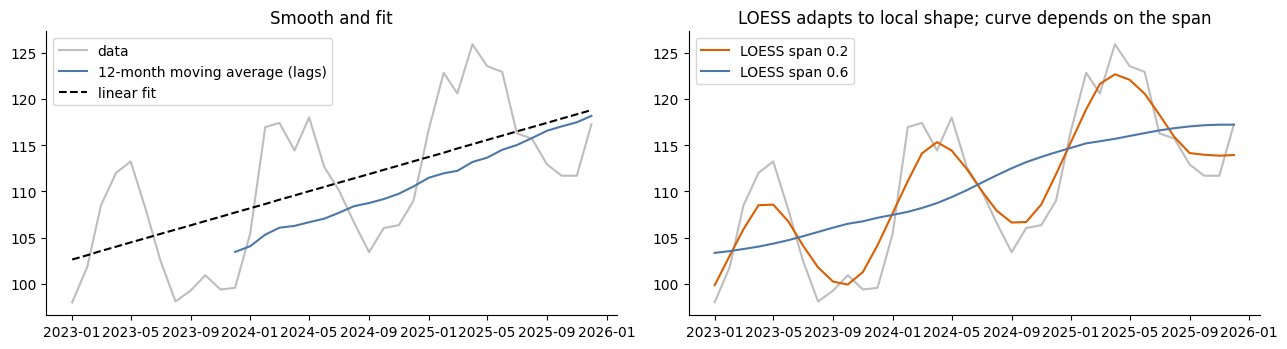

Describe -> Sales rose by about 0.46 units per month (±0.20); the trend is distinguishable from zero (Kendall τ = 0.40, p = 5.4e-04).


In [16]:
rs = np.random.default_rng(5)
t = np.arange(36)
y = 100 + 0.65 * t + 9 * np.sin(2 * np.pi * t / 12) + rs.normal(0, 2.5, 36)
idx = pd.period_range("2023-01", periods=36, freq="M").to_timestamp()

def loess(x, y, frac=0.4):
    n, k, out = len(x), int(np.ceil(frac * len(x))), np.zeros(len(x))
    for i in range(n):
        dd = np.abs(x - x[i]); nb = np.argsort(dd)[:k]; h = dd[nb].max() + 1e-9
        wt = (1 - (dd[nb] / h) ** 3) ** 3
        X = np.c_[np.ones(k), x[nb] - x[i]]; W = np.diag(wt)
        out[i] = np.linalg.solve(X.T @ W @ X, X.T @ W @ y[nb])[0]
    return out

lr = stats.linregress(t, y)
tau, p_mk = stats.kendalltau(t, y)
ma = pd.Series(y).rolling(12, center=False).mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(idx, y, color=GREY, label="data"); ax[0].plot(idx, ma, color=BLUE, label="12-month moving average (lags)")
ax[0].plot(idx, lr.intercept + lr.slope * t, "--", color="k", label="linear fit"); ax[0].legend(); ax[0].set_title("Smooth and fit")
ax[1].plot(idx, y, color=GREY)
for fr, c in [(0.2, ACCENT), (0.6, BLUE)]:
    ax[1].plot(idx, loess(t.astype(float), y, fr), color=c, label=f"LOESS span {fr}")
ax[1].legend(); ax[1].set_title("LOESS adapts to local shape; curve depends on the span")
plt.tight_layout(); plt.show()

def describe_trend(slope, se, tau, p, unit="units per month"):
    direction = "rose" if slope > 0 else "fell"
    sig = "distinguishable from zero" if p < 0.05 else "not distinguishable from zero"
    return f"Sales {direction} by about {abs(slope):.2f} {unit} (±{1.96 * se:.2f}); the trend is {sig} (Kendall τ = {tau:.2f}, p = {p:.1e})."
print("Describe ->", describe_trend(lr.slope, lr.stderr, tau, p_mk))

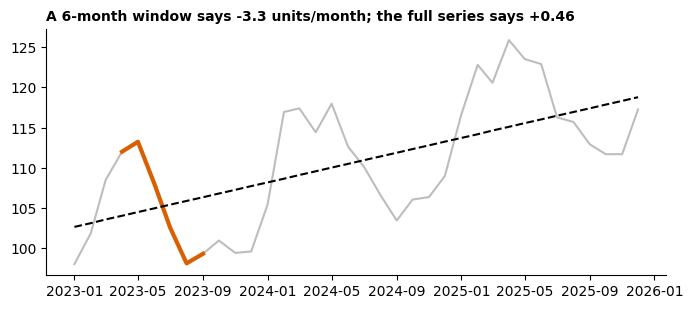

Always show the full series next to any trend sentence.


In [17]:
# Caution: a trend over a short or seasonal window can reverse. Find the most misleading 6-month window.
win = min(range(0, 31), key=lambda s: stats.linregress(t[s:s + 6], y[s:s + 6]).slope)
sl = stats.linregress(t[win:win + 6], y[win:win + 6])
plt.figure(figsize=(8, 3.2)); plt.plot(idx, y, color=GREY); plt.plot(idx[win:win + 6], y[win:win + 6], color=ACCENT, lw=3)
plt.plot(idx, lr.intercept + lr.slope * t, "--", color="k")
plt.title(f"A 6-month window says {sl.slope:+.1f} units/month; the full series says {lr.slope:+.2f}", loc="left", fontweight="bold", fontsize=10); plt.show()
print("Always show the full series next to any trend sentence.")

## 9 · Automatic identification of correlations

$$r=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2\,\sum (y_i-\bar y)^2}}$$

*r* lies in [−1, 1]; it is symmetric; unchanged by shifting (x + C) or rescaling (C·x). *n* variables give *n(n−1)/2* pairs.

### Numerical 1: Pearson r by hand (ad spend vs sales, five stores)

In [18]:
store = pd.DataFrame({"Store": list("ABCDE"), "x (ad spend)": [1, 2, 3, 4, 5], "y (sales)": [2, 4, 5, 4, 5]})
xb, yb = store["x (ad spend)"].mean(), store["y (sales)"].mean()
store["x - x̄"] = store["x (ad spend)"] - xb; store["y - ȳ"] = store["y (sales)"] - yb
store["(x-x̄)(y-ȳ)"] = store["x - x̄"] * store["y - ȳ"]; store["(x-x̄)²"] = store["x - x̄"] ** 2; store["(y-ȳ)²"] = store["y - ȳ"] ** 2
display(store)
num_, den_ = store["(x-x̄)(y-ȳ)"].sum(), np.sqrt(store["(x-x̄)²"].sum() * store["(y-ȳ)²"].sum())
r_hand = num_ / den_
print(f"r = {num_:.0f} / sqrt({store['(x-x̄)²'].sum():.0f} x {store['(y-ȳ)²'].sum():.0f}) = {r_hand:.3f}   (numpy says {np.corrcoef(store['x (ad spend)'], store['y (sales)'])[0, 1]:.3f})")
x_ = store["x (ad spend)"]
print("Rescaled x*100:", round(np.corrcoef(x_ * 100, store["y (sales)"])[0, 1], 3), "| shifted x+7:", round(np.corrcoef(x_ + 7, store["y (sales)"])[0, 1], 3), "-> r unchanged")
rr, pp = stats.pearsonr(x_, store["y (sales)"])
print(f"With n = 5, p = {pp:.2f}: an AI should call this tentative, not a finding.")

,Store,x (ad spend),y (sales),x - x̄,y - ȳ,(x-x̄)(y-ȳ),(x-x̄)²,(y-ȳ)²
0,A,1,2,-2.0,-2.0,4.0,4.0,4.0
1,B,2,4,-1.0,0.0,-0.0,1.0,0.0
2,C,3,5,0.0,1.0,0.0,0.0,1.0
3,D,4,4,1.0,0.0,0.0,1.0,0.0
4,E,5,5,2.0,1.0,2.0,4.0,1.0


r = 6 / sqrt(10 x 6) = 0.775   (numpy says 0.775)
Rescaled x*100: 0.775 | shifted x+7: 0.775 -> r unchanged
With n = 5, p = 0.12: an AI should call this tentative, not a finding.


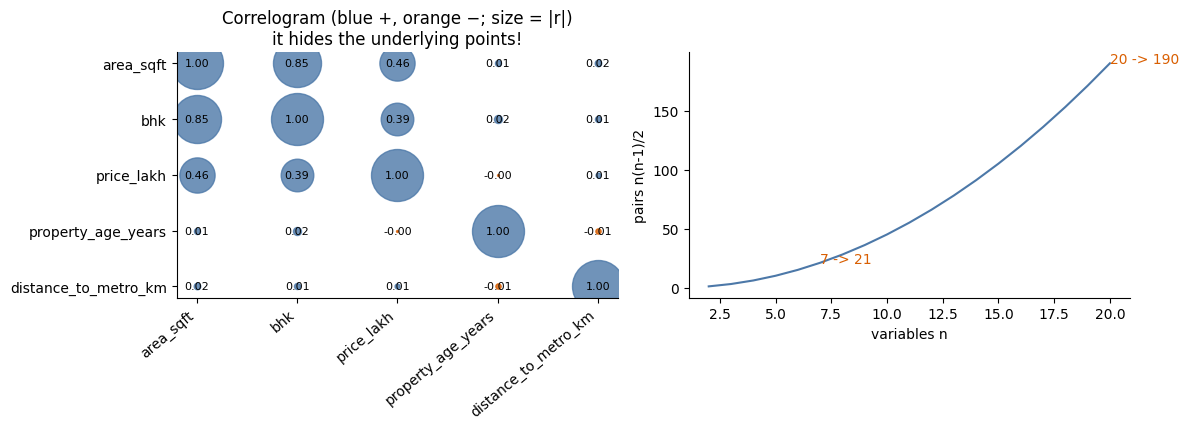

In [19]:
# Correlogram with circle size = |r| (Wilke Fig. 12-7), and the pair-count growth
cols = ["area_sqft", "bhk", "price_lakh", "property_age_years", "distance_to_metro_km"]
cm = d[cols].corr().values
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for i in range(len(cols)):
    for j in range(len(cols)):
        ax[0].scatter(j, len(cols) - 1 - i, s=abs(cm[i, j]) * 1400, color=BLUE if cm[i, j] > 0 else ACCENT, alpha=.8)
        ax[0].text(j, len(cols) - 1 - i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[0].set_xticks(range(len(cols))); ax[0].set_xticklabels(cols, rotation=40, ha="right"); ax[0].set_yticks(range(len(cols))); ax[0].set_yticklabels(cols[::-1])
ax[0].set_title("Correlogram (blue +, orange −; size = |r|)\nit hides the underlying points!")
ks = np.arange(2, 21); ax[1].plot(ks, ks * (ks - 1) / 2, color=BLUE); ax[1].set_xlabel("variables n"); ax[1].set_ylabel("pairs n(n-1)/2")
for k_ in (7, 20): ax[1].annotate(f"{k_} -> {k_ * (k_ - 1) // 2}", (k_, k_ * (k_ - 1) / 2), color=ACCENT)
plt.tight_layout(); plt.show()

### Same statistics, different data: Anscombe's quartet
> *"It is always better to visualize the raw data rather than abstract, derived quantities that have been calculated from it."* (Wilke, Ch 12)

,mean x,mean y,var y,r
I,9.0,7.5,4.13,0.82
II,9.0,7.5,4.13,0.82
III,9.0,7.5,4.12,0.82
IV,9.0,7.5,4.12,0.82


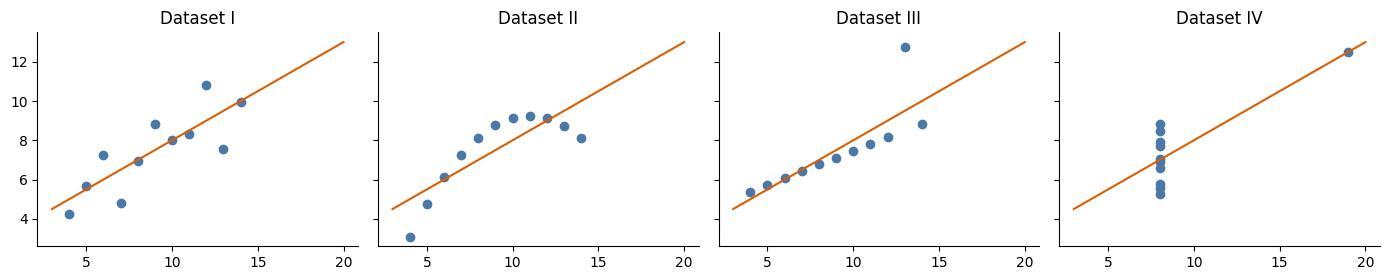

Lesson: require a chart for every correlation an AI reports.


In [20]:
x123 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
aq = {"I": (x123, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
      "II": (x123, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
      "III": (x123, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
      "IV": ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89])}
summ = pd.DataFrame({k: {"mean x": np.mean(v[0]), "mean y": np.mean(v[1]), "var y": np.var(v[1], ddof=1), "r": np.corrcoef(*v)[0, 1]} for k, v in aq.items()}).T.round(2)
display(summ)
fig, ax = plt.subplots(1, 4, figsize=(14, 2.9), sharex=True, sharey=True)
for a, (k, (xx, yy)) in zip(ax, aq.items()):
    a.scatter(xx, yy, color=BLUE); b1, b0 = np.polyfit(xx, yy, 1); g = np.array([3, 20]); a.plot(g, b0 + b1 * g, color=ACCENT); a.set_title(f"Dataset {k}")
plt.tight_layout(); plt.show()
print("Lesson: require a chart for every correlation an AI reports.")

## 10 · Automatic identification of patterns: clusters and PCA

PCA standardizes variables and builds uncorrelated **principal components**; PC 1 captures the most variation. Interpret two things: the **composition of each PC** (arrows) and **where points fall**.
**AI role:** compute PCA, propose clusters, flag the odd listing. **Human role:** decide whether *Budget / Mid / Premium* are meaningful segments or artefacts.

explained variance: [0.47 0.2 ] | loadings:
                        PC1   PC2
log_price             0.52 -0.01
area_sqft             0.62  0.00
bhk                   0.59  0.01
property_age_years    0.02  0.72
distance_to_metro_km  0.02 -0.70
silhouette by k (AI's evidence for choosing k): {2: np.float64(0.28), 3: np.float64(0.23), 4: np.float64(0.23), 5: np.float64(0.21)}


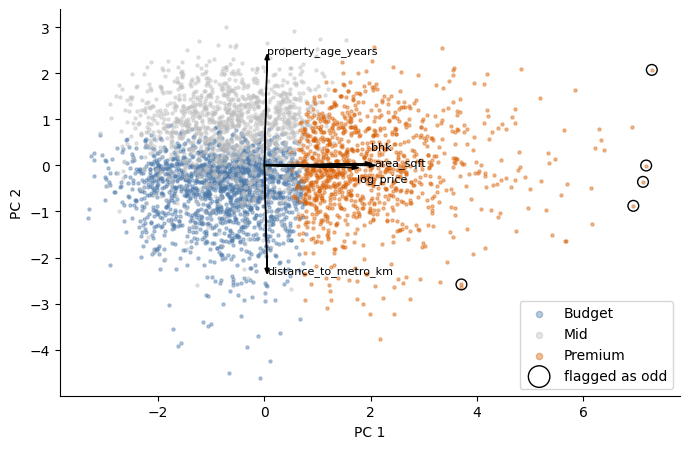

Segment means:


,price_lakh,area_sqft,bhk,property_age_years,distance_to_metro_km
segment,,,,,
Budget,77.3,957.6,1.8,4.9,3.1
Mid,78.9,988.5,1.9,19.3,3.0
Premium,179.5,1759.5,3.5,10.3,3.1


Human check: 'Budget' and 'Mid' have almost the same price (₹77.3 vs ₹78.9 lakh); they differ in age (4.9 vs 19.3 yrs) and metro distance. The labels came from a naming rule, not from the data: only 'Premium' is a price segment. The AI proposed; the human must rename.
Flagged odd listings (AI flags, human decides):


,city,area_sqft,bhk,price_lakh,property_age_years
824,Chennai,2579.0,5,102.2,23.5
314,Mumbai,3813.0,6,549.1,28.1
43,Mumbai,2721.0,6,2496.7,5.8
233,Pune,4087.0,6,251.8,3.3
3230,Mumbai,3846.0,6,456.4,19.2


In [21]:
feat = d.assign(log_price=np.log(d.price_lakh))[["log_price", "area_sqft", "bhk", "property_age_years", "distance_to_metro_km"]]
Z = StandardScaler().fit_transform(feat)
pca = PCA(n_components=2).fit(Z); P = pca.transform(Z)
print("explained variance:", pca.explained_variance_ratio_.round(2), "| loadings:\n", pd.DataFrame(pca.components_.T, index=feat.columns, columns=["PC1", "PC2"]).round(2))

sil = {k: round(silhouette_score(Z, KMeans(k, n_init=5, random_state=0).fit_predict(Z), sample_size=1500, random_state=0), 2) for k in (2, 3, 4, 5)}
print("silhouette by k (AI's evidence for choosing k):", sil)
km = KMeans(3, n_init=10, random_state=0).fit(Z)
rank = pd.Series(d.price_lakh.values).groupby(km.labels_).mean().rank().astype(int)
names = {c: ["Budget", "Mid", "Premium"][r - 1] for c, r in rank.items()}
seg = pd.Series(km.labels_).map(names).values
dist_c = np.linalg.norm(Z - km.cluster_centers_[km.labels_], axis=1); odd = np.argsort(-dist_c)[:5]

fig, ax = plt.subplots(figsize=(7, 4.6))
for s_, c_ in zip(["Budget", "Mid", "Premium"], [BLUE, GREY, ACCENT]):
    ax.scatter(P[seg == s_, 0], P[seg == s_, 1], s=5, alpha=.4, color=c_, label=s_)
ax.scatter(P[odd, 0], P[odd, 1], s=60, facecolors="none", edgecolors="k", label="flagged as odd")
for k_, ((a_, b_), n_) in enumerate(zip(pca.components_.T * 3.2, feat.columns)):
    ax.arrow(0, 0, a_, b_, color="k", head_width=.08)
    ax.text(a_ * 1.05, b_ * 1.05 + (0.3 * (k_ - 1) if abs(b_) < 0.3 else 0), n_, fontsize=8)
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(markerscale=2, loc="lower right"); plt.tight_layout(); plt.show()
segm = d.assign(segment=seg).groupby("segment")[["price_lakh", "area_sqft", "bhk", "property_age_years", "distance_to_metro_km"]].mean().round(1).loc[["Budget", "Mid", "Premium"]]
print("Segment means:"); display(segm)
print(f"Human check: 'Budget' and 'Mid' have almost the same price (₹{segm.loc['Budget', 'price_lakh']} vs ₹{segm.loc['Mid', 'price_lakh']} lakh); "
      f"they differ in age ({segm.loc['Budget', 'property_age_years']} vs {segm.loc['Mid', 'property_age_years']} yrs) and metro distance. "
      "The labels came from a naming rule, not from the data: only 'Premium' is a price segment. The AI proposed; the human must rename.")
print("Flagged odd listings (AI flags, human decides):"); display(d.iloc[odd][["city", "area_sqft", "bhk", "price_lakh", "property_age_years"]])

## 11 · Numerical 2: scanning many pairs produces false patterns

An assistant scans all pairs of 7 variables and calls any pair with p < 0.05 "significant". Suppose **no real correlations exist**.

(a) pairs tested            = 7 x 6 / 2 = 21
(b) expected false findings = 21 x 0.05 = 1.05
(c) P(at least one false)   = 1 - 0.95^21 = 0.659
(d) Bonferroni threshold    = 0.05 / 21 = 0.0024

Simulation: mean false 'significant' pairs = 1.06; at least one in 67% of runs
With Bonferroni: at least one false finding in 5.5% of runs
MCQ check: 8 variables -> 28 pairs -> 1.40 expected false findings


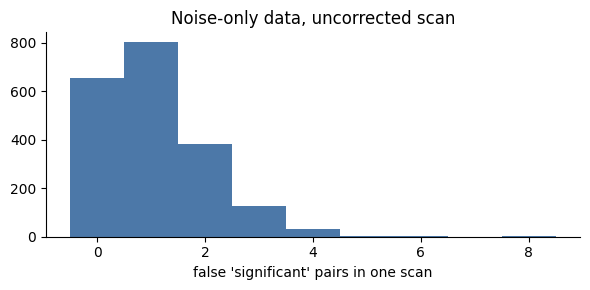

Lesson: 'the strongest correlation' from a big scan is often noise. Treat scan results as hypotheses and confirm on new data.


In [22]:
k = 7
pairs = k * (k - 1) // 2
print(f"(a) pairs tested            = {k} x {k - 1} / 2 = {pairs}")
print(f"(b) expected false findings = {pairs} x 0.05 = {pairs * 0.05:.2f}")
print(f"(c) P(at least one false)   = 1 - 0.95^{pairs} = {1 - 0.95 ** pairs:.3f}")
print(f"(d) Bonferroni threshold    = 0.05 / {pairs} = {0.05 / pairs:.4f}")

# Simulate it: 7 pure-noise columns, n = 200 rows, repeated 2000 times
rs = np.random.default_rng(0); n, runs = 200, 2000
iu = np.triu_indices(k, 1); hits_raw, hits_bonf = [], []
for _ in range(runs):
    R = np.corrcoef(rs.normal(size=(n, k)).T)[iu]
    p = 2 * stats.t.sf(np.abs(R * np.sqrt((n - 2) / (1 - R ** 2))), n - 2)
    hits_raw.append((p < 0.05).sum()); hits_bonf.append((p < 0.05 / pairs).sum())
hits_raw, hits_bonf = np.array(hits_raw), np.array(hits_bonf)
print(f"\nSimulation: mean false 'significant' pairs = {hits_raw.mean():.2f}; at least one in {np.mean(hits_raw >= 1):.0%} of runs")
print(f"With Bonferroni: at least one false finding in {np.mean(hits_bonf >= 1):.1%} of runs")
print(f"MCQ check: 8 variables -> {8 * 7 // 2} pairs -> {8 * 7 // 2 * 0.05:.2f} expected false findings")
plt.figure(figsize=(6, 3)); plt.hist(hits_raw, bins=np.arange(-.5, hits_raw.max() + 1.5), color=BLUE); plt.xlabel("false 'significant' pairs in one scan"); plt.title("Noise-only data, uncorrected scan")
plt.tight_layout(); plt.show()
print("Lesson: 'the strongest correlation' from a big scan is often noise. Treat scan results as hypotheses and confirm on new data.")

## 12 · LLM-generated hypotheses

**Generate vs verify** (Munzner): the LLM is good at *fast, broad generation* using world knowledge; it is weak at unrecorded causes and may present guesses as facts. Ask for **several competing hypotheses and the evidence that would separate them.** The cheapest one to rule out first is a **data problem**.

Synthetic case: monthly unit sales for 12 stores over 24 months. **Observation: October 2025 sales fell sharply.**

In [23]:
rs = np.random.default_rng(7)
months = pd.period_range("2023-11", "2025-10", freq="M")
store_ids = [f"S{i}" for i in range(1, 13)]
base = rs.normal(400, 50, 12).clip(250)
rows = []
for ti, mth in enumerate(months):
    season = 1 + 0.10 * np.sin(2 * np.pi * (mth.month - 3) / 12)
    price_idx = 104 if mth >= pd.Period("2025-09") else 100             # 4% price rise in Sept 2025
    for s, b in zip(store_ids, base):
        if mth == pd.Period("2025-10") and s in ("S10", "S11", "S12"):
            continue                                                       # logging outage: no rows (planted)
        rows.append((str(mth), s, rs.poisson(b * season * (1 + 0.004 * ti) * (0.97 if price_idx > 100 else 1)), price_idx))
sales = pd.DataFrame(rows, columns=["month", "store", "units", "price_index"])
tot = sales.groupby("month").units.sum()
print(f"Total units: Sep 2025 = {tot['2025-09']:,} | Oct 2025 = {tot['2025-10']:,} | change = {(tot['2025-10'] / tot['2025-09'] - 1) * 100:.0f}%")

hyp = pd.DataFrame([
    ("Oct sales fell", "Price rise in September", "Sales vs price, before/after", "medium"),
    ("", "Festival shifted to November", "Same month, previous years", "medium"),
    ("", "3 stores missing data", "Row counts per store per month", "lowest"),
    ("", "Competitor promotion", "Needs outside data we do not have", "high")],
    columns=["Observation", "LLM hypothesis", "Test (chart / statistic)", "cost to rule out"])
display(hyp)

Total units: Sep 2025 = 5,028 | Oct 2025 = 3,527 | change = -30%


,Observation,LLM hypothesis,Test (chart / statistic),cost to rule out
0,Oct sales fell,Price rise in September,"Sales vs price, before/after",medium
1,,Festival shifted to November,"Same month, previous years",medium
2,,3 stores missing data,Row counts per store per month,lowest
3,,Competitor promotion,Needs outside data we do not have,high


In [24]:
# Test the cheapest hypothesis first: row counts per store per month
counts = sales.pivot_table(index="store", columns="month", values="units", aggfunc="count").iloc[:, -3:]
print("Rows per store (last 3 months):"); display(counts.T)
missing = counts.index[counts["2025-10"].isna()].tolist()
print("Stores with no October rows:", missing)

# Like-for-like on stores that exist in both months
both = sales[sales.store.isin(set(sales[sales.month == "2025-10"].store))]
lfl = both.groupby("month").units.sum()
print(f"Like-for-like (9 stores): Oct vs Sep = {(lfl['2025-10'] / lfl['2025-09'] - 1) * 100:+.0f}%   <- the 'drop' is a data problem")

# Festival-shift hypothesis: is Oct normally lower than Sep? Compare with last year's pattern
ratio24 = tot["2024-10"] / tot["2024-09"]
print(f"Last year Oct/Sep ratio = {ratio24:.2f}; this year (like-for-like) = {lfl['2025-10'] / lfl['2025-09']:.2f} -> no shift in the seasonal pattern")
# Price-rise hypothesis: Sep/Aug this year vs the same ratio last year (removes seasonality)
sa = lambda y: sales[(sales.month == f"{y}-09")].units.sum() / sales[(sales.month == f"{y}-08")].units.sum()
eff = (sa(2025) / sa(2024) - 1) * 100
drop_all = (tot["2025-10"] / tot["2025-09"] - 1) * 100
print(f"Price rise: Sep/Aug ratio is {eff:+.0f}% vs last year's pattern -> a much smaller effect; it cannot explain a {drop_all:.0f}% fall")

Rows per store (last 3 months):


store,S1,S10,S11,S12,S2,S3,S4,S5,S6,S7,S8,S9
month,,,,,,,,,,,,
2025-08,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2025-09,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2025-10,1.0,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Stores with no October rows: ['S10', 'S11', 'S12']
Like-for-like (9 stores): Oct vs Sep = -6%   <- the 'drop' is a data problem
Last year Oct/Sep ratio = 0.94; this year (like-for-like) = 0.94 -> no shift in the seasonal pattern
Price rise: Sep/Aug ratio is -7% vs last year's pattern -> a much smaller effect; it cannot explain a -30% fall


**Ask what else differs.** A hypothesis about *rating ~ distance to metro* ("commute matters to buyers") must be tested while controlling for price and city.

In [25]:
rt = d.dropna(subset=["rating"]).copy()
r_raw = rt.rating.corr(rt.distance_to_metro_km)
Xc = pd.get_dummies(rt.city, drop_first=True).assign(logp=np.log(rt.price_lakh)).astype(float)
res = lambda v: v - np.c_[np.ones(len(Xc)), Xc.values] @ np.linalg.lstsq(np.c_[np.ones(len(Xc)), Xc.values], v, rcond=None)[0]
r_part = np.corrcoef(res(rt.rating.values), res(rt.distance_to_metro_km.values))[0, 1]
print(f"rating ~ distance: raw r = {r_raw:.2f}; after controlling for city and price r = {r_part:.2f}  -> the hypothesis survives")

rating ~ distance: raw r = -0.58; after controlling for city and price r = -0.58  -> the hypothesis survives


### When AI hypotheses go wrong: Simpson's paradox
An LLM finds Hospital A has a lower overall survival rate than B and concludes A gives worse care. **A lurking variable (case severity)** differs between the groups and reverses the comparison. *Human safeguard: ask what else differs between the groups, and split by it before accepting a causal claim.*

,patients,survived,rate
hospital,,,
A,500,319,63.8
B,500,434,86.8


hospital,A,B
severity,,
Mild,98.0,96.0
Severe,60.0,50.0


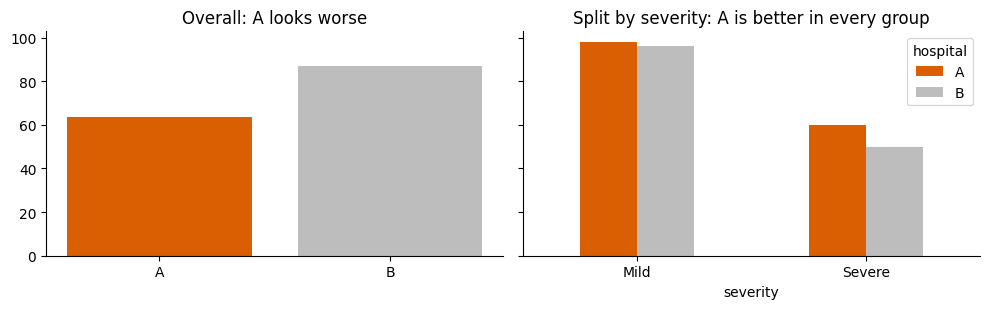

Why: Hospital A treats mostly severe cases ( 90 % of its patients) vs B ( 20 %).


In [26]:
hosp = pd.DataFrame({"hospital": ["A", "A", "B", "B"], "severity": ["Mild", "Severe", "Mild", "Severe"],
                     "patients": [50, 450, 400, 100], "survived": [49, 270, 384, 50]})
overall = hosp.groupby("hospital")[["patients", "survived"]].sum().assign(rate=lambda t: t.survived / t.patients * 100).round(1)
hosp["rate_%"] = (hosp.survived / hosp.patients * 100).round(1)
display(overall); display(hosp.pivot(index="severity", columns="hospital", values="rate_%"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
ax[0].bar(overall.index, overall.rate, color=[ACCENT, GREY]); ax[0].set_title("Overall: A looks worse")
pv = hosp.pivot(index="severity", columns="hospital", values="rate_%"); pv.plot.bar(ax=ax[1], color=[ACCENT, GREY], rot=0); ax[1].set_title("Split by severity: A is better in every group")
plt.tight_layout(); plt.show()
print("Why: Hospital A treats mostly severe cases (", int(450 / 500 * 100), "% of its patients) vs B (", int(100 / 500 * 100), "%).")

## 13 · Data interpretation using natural language

An LLM can **caption charts**, **answer questions from the data**, **explain statistics**, and **translate for audiences**. The *risk zone* is predictions and causal explanations: they need evidence and uncertainty. Ask the AI which **level** each sentence belongs to: *read the data*, *read between the data*, *read beyond the data*.

In [27]:
mo = d.groupby(d.listed_date.dt.to_period("M")).size()

def chart_to_text(series, name="Monthly listings"):
    hi, lo = series.idxmax(), series.idxmin()
    chg = (series.iloc[-1] / series.iloc[0] - 1) * 100
    caption = f"{name}: {chg:+.0f}% from {series.index[0]} to {series.index[-1]}; highest in {hi} ({series.max()}), lowest in {lo} ({series.min()})."
    alt = f"Line chart of {name.lower()} by month, {series.index[0]} to {series.index[-1]}, generally {'rising' if chg > 0 else 'falling'}."
    return caption, alt

def answer_question(q):
    q = q.lower()
    if "lowest month" in q:
        return f"{mo.idxmin()} had the fewest listings ({mo.min()}).", "mo.idxmin()"
    if "highest" in q and "price" in q:
        m_ = d.groupby("city").price_lakh.median(); return f"{m_.idxmax()} has the highest median price (₹{m_.max():.0f} lakh).", "d.groupby('city').price_lakh.median().idxmax()"
    if "missing" in q:
        return f"{d.rating.isna().mean():.0%} of ratings are missing.", "d.rating.isna().mean()"
    return "I cannot answer that from the data provided.", "-"

def explain_r(r, x, y):
    s = "strong" if abs(r) > .7 else "moderate" if abs(r) > .4 else "weak"
    return f"r = {r:.2f}: a {s} {'positive' if r > 0 else 'negative'} association; higher {x} tends to go with {'higher' if r > 0 else 'lower'} {y}, but {x} is not the only factor and this does not prove cause."

def for_audience(text_stats, audience):
    return text_stats["analyst"] if audience == "analyst" else text_stats["manager"]

cap, alt = chart_to_text(mo)
print("CAPTION :", cap); print("ALT-TEXT:", alt)
for q in ["Which month was the lowest month?", "Which city has the highest price?", "How much data is missing?", "Will prices rise next year?"]:
    a, c = answer_question(q); print(f"Q: {q}\nA: {a}   [code: {c}]")
print(explain_r(d.area_sqft.corr(d.price_lakh), "area", "price"))
info = {"analyst": f"Price skew = {d.price_lakh.skew():.1f}; median ₹{d.price_lakh.median():.0f} lakh vs mean ₹{d.price_lakh.mean():.0f} lakh; use medians and log scale.",
        "manager": f"A typical home costs about ₹{d.price_lakh.median():.0f} lakh; a few very expensive homes make the 'average' look higher."}
for aud in ("analyst", "manager"): print(f"For the {aud}:", for_audience(info, aud))

CAPTION : Monthly listings: +33% from 2025-01 to 2025-12; highest in 2025-12 (372), lowest in 2025-02 (269).
ALT-TEXT: Line chart of monthly listings by month, 2025-01 to 2025-12, generally rising.
Q: Which month was the lowest month?
A: 2025-02 had the fewest listings (269).   [code: mo.idxmin()]
Q: Which city has the highest price?
A: Mumbai has the highest median price (₹155 lakh).   [code: d.groupby('city').price_lakh.median().idxmax()]
Q: How much data is missing?
A: 30% of ratings are missing.   [code: d.rating.isna().mean()]
Q: Will prices rise next year?
A: I cannot answer that from the data provided.   [code: -]
r = 0.46: a moderate positive association; higher area tends to go with higher price, but area is not the only factor and this does not prove cause.
For the analyst: Price skew = 8.4; median ₹81 lakh vs mean ₹105 lakh; use medians and log scale.
For the manager: A typical home costs about ₹81 lakh; a few very expensive homes make the 'average' look higher.


### Good and poor natural-language interpretations
Wilke's vocabulary: **ugly** = aesthetic problem · **bad** = perception problem (unclear, misleading) · **wrong** = mathematically incorrect. Below, a simple rule-based checker plays the human's first-pass filter; anything it flags goes to a person.

In [28]:
CAUSAL = r"\b(cause[sd]?|because|due to|drives?|led to|results? in)\b"
PRED = r"\b(will|going to)\b"
HEDGE = r"\b(may|might|could|likely|if|uncertain|uncertainty)\b"

def check_statement(s):
    f = []
    if re.search(CAUSAL, s, re.I) and re.search(r"\br\s*=", s): f.append("correlation stated as causation")
    if re.search(r"\baverage\b", s, re.I) and "median" not in s.lower(): f.append("'average' of a skewed measure: check skew")
    if re.search(PRED, s, re.I) and not re.search(HEDGE, s, re.I): f.append("prediction with no uncertainty")
    if not re.search(r"\d", s): f.append("vague: no number, adds nothing")
    if re.search(r"(doubled|%)", s) and not re.search(r"(like-for-like|stores with data)", s, re.I): f.append("numeric comparison: recompute like-for-like, check completeness")
    return "; ".join(f) or "no flag"

def level(s):
    if re.search(PRED, s, re.I) or re.search(CAUSAL, s, re.I): return "beyond"
    if re.search(r"(higher|lower|tend|correlat|than|relationship|compared)", s, re.I): return "between"
    return "data"

table = pd.DataFrame([
    ("Ad spend causes sales to rise (r = 0.78).", "Bad", "Stores with higher ad spend tended to have higher sales."),
    ("Average price is ₹84 lakh.", "Bad", "Median price is ₹68.5 lakh; a few luxury homes raise the mean to ₹84 lakh."),
    ("Pune sales doubled in Q2.", "Wrong", "For the 3 stores with data in both quarters, sales were flat."),
    ("Sales will recover in December.", "Bad", "If the usual seasonal pattern holds, sales may rise; uncertainty is high."),
    ("The data show interesting variation.", "Ugly", "Prices vary 3x across cities, from ₹66 to ₹148 lakh."),
], columns=["AI statement", "Expert rating", "Better statement"])
table["First-pass flag"] = table["AI statement"].map(check_statement)
table["Level"] = table["AI statement"].map(level)
display(table[["AI statement", "Level", "First-pass flag", "Expert rating"]])
print("Over-claiming grows upwards: read the data < read between the data < read beyond the data.")

,AI statement,Level,First-pass flag,Expert rating
0,Ad spend causes sales to rise (r = 0.78).,beyond,correlation stated as causation,Bad
1,Average price is ₹84 lakh.,data,'average' of a skewed measure: check skew,Bad
2,Pune sales doubled in Q2.,data,"numeric comparison: recompute like-for-like, c...",Wrong
3,Sales will recover in December.,beyond,prediction with no uncertainty; vague: no numb...,Bad
4,The data show interesting variation.,data,"vague: no number, adds nothing",Ugly


Over-claiming grows upwards: read the data < read between the data < read beyond the data.


## 14 · Human-in-the-loop AI visualization: AI as assistant, not replacement

> *"Vis systems are appropriate for use when your goal is to **augment** human capabilities, rather than completely replace the human in the loop."* (Munzner §1.2)

**Why keep humans?** Problems are **ill-specified** (people don't know in advance which questions are right); exploration needs human judgement. Full automation is fine when a trusted automatic solution is acceptable (e.g. high-frequency trading): most EDA is not like that.

### The human-in-the-loop cycle
**1. AI proposes → 2. Visualize the evidence → 3. Human inspects → 4. Decide: accept / correct / reject → 5. Feedback shapes the next proposal.**
*Without step 2 the human can only trust or distrust; with it, the human can verify.*

### Choosing the level of automation
Stakes and reversibility decide. A wrong exploratory chart costs minutes; a wrong board-report insight costs decisions. **Raise automation only where errors are cheap and visible.** (Heer 2019: agency plus automation.)

In [29]:
def recommended_automation(stakes, reversible, errors_visible):
    score = (stakes == "low") + reversible + errors_visible
    return {3: "High: AI may act, human spot-checks", 2: "Medium: AI proposes, human approves", }.get(score, "Low: human decides, AI drafts only")

cases = [("Exploratory chart in a notebook", "low", True, True), ("Weekly ops dashboard refresh", "low", True, False),
         ("Board-report insight", "high", False, False), ("Auto-send customer pricing email", "high", False, True)]
display(pd.DataFrame([(n, s, r, v, recommended_automation(s, r, v)) for n, s, r, v in cases],
                     columns=["Task", "Stakes", "Reversible?", "Errors visible?", "Suggested automation level"]))

,Task,Stakes,Reversible?,Errors visible?,Suggested automation level
0,Exploratory chart in a notebook,low,True,True,"High: AI may act, human spot-checks"
1,Weekly ops dashboard refresh,low,True,False,"Medium: AI proposes, human approves"
2,Board-report insight,high,False,False,"Low: human decides, AI drafts only"
3,Auto-send customer pricing email,high,False,True,"Low: human decides, AI drafts only"


### Interactive refinement of AI recommendations
| Feedback | Example | Effect |
|---|---|---|
| Reject | "not this chart" | down-weights similar charts |
| Constrain | "no pies" | hard rule for the session |
| Steer | "focus on price & area" | re-ranks by relevance |
| Adjust | "use 5-year bins" | changes a parameter |
| Pin | "keep this one" | fixed in the dashboard |

Good systems make feedback **cheap** (one call), **visible** (show what changed) and **reversible** (undo). The small simulator below does exactly that.

In [30]:
class ChartAdvisor:
    def __init__(self, candidates):
        self.cands = {c["id"]: c for c in candidates}
        self.state = dict(banned=set(), steer=set(), rejected=set(), params={}, pinned=[])
        self.history = []

    def score(self, c):
        s = c["base"] + 0.15 * len(self.state["steer"] & set(c["fields"]))
        if c["id"] in self.state["rejected"]: s *= 0.3
        s *= 0.8 ** sum(1 for r in self.state["rejected"] if r != c["id"] and self.cands[r]["type"] == c["type"])
        return s

    def ranked(self):
        live = [c for c in self.cands.values() if c["type"] not in self.state["banned"]]
        return sorted(live, key=lambda c: (c["id"] not in self.state["pinned"], -self.score(c)))

    def _act(self, label, fn, top=5):
        before = [c["id"] for c in self.ranked()]
        self.history.append((label, copy.deepcopy(self.state))); fn()
        after = self.ranked()
        print(f"\n> {label}")
        for i, c in enumerate(after[:top], 1):
            note = "new" if c["id"] not in before else ("" if before.index(c["id"]) == i - 1 else f"{'up' if before.index(c['id']) > i - 1 else 'down'} from #{before.index(c['id']) + 1}")
            pin = " [pinned]" if c["id"] in self.state["pinned"] else ""
            prm = f" {self.state['params'].get(c['id'], '')}" if c["id"] in self.state["params"] else ""
            print(f"   {i}. {c['title']} ({c['type']}){pin}{prm}  score={self.score(c):.2f} {note}")
        gone = [self.cands[b]["title"] for b in before if b not in [c["id"] for c in after]]
        if gone: print("   removed:", ", ".join(gone))

    def start(self): self._act("AI's first proposal", lambda: None)
    def reject(self, cid): self._act(f"Reject '{self.cands[cid]['title']}'", lambda: self.state["rejected"].add(cid))
    def constrain(self, ctype): self._act(f"Constrain: no {ctype} charts", lambda: self.state["banned"].add(ctype))
    def steer(self, *fields): self._act(f"Steer: focus on {', '.join(fields)}", lambda: self.state["steer"].update(fields))
    def adjust(self, cid, **kw): self._act(f"Adjust '{self.cands[cid]['title']}': {kw}", lambda: self.state["params"].__setitem__(cid, kw))
    def pin(self, cid): self._act(f"Pin '{self.cands[cid]['title']}'", lambda: self.state["pinned"].append(cid))
    def undo(self):
        label, snap = self.history.pop(); self.state = snap
        print(f"\n< Undo: '{label}' reverted"); self._act("(current ranking)", lambda: None)

cands = [dict(id="hist", type="histogram", title="Price distribution", fields=["price_lakh"], base=.70),
         dict(id="box", type="boxplot", title="Price by city", fields=["price_lakh", "city"], base=.72),
         dict(id="pie", type="pie", title="City share of listings", fields=["city"], base=.55),
         dict(id="sc", type="scatter", title="Area vs price", fields=["area_sqft", "price_lakh"], base=.74),
         dict(id="bar", type="bar", title="Median price by city", fields=["city", "price_lakh"], base=.68),
         dict(id="line", type="line", title="Listings per month", fields=["listed_date"], base=.60),
         dict(id="heat", type="heatmap", title="Correlation matrix", fields=["area_sqft", "bhk", "price_lakh"], base=.58)]
adv = ChartAdvisor(cands)
adv.start(); adv.reject("box"); adv.constrain("pie"); adv.steer("price_lakh", "area_sqft")
adv.adjust("hist", bin_width="5 lakh"); adv.pin("sc"); adv.undo()


> AI's first proposal
   1. Area vs price (scatter)  score=0.74 
   2. Price by city (boxplot)  score=0.72 
   3. Price distribution (histogram)  score=0.70 
   4. Median price by city (bar)  score=0.68 
   5. Listings per month (line)  score=0.60 

> Reject 'Price by city'
   1. Area vs price (scatter)  score=0.74 
   2. Price distribution (histogram)  score=0.70 up from #3
   3. Median price by city (bar)  score=0.68 up from #4
   4. Listings per month (line)  score=0.60 up from #5
   5. Correlation matrix (heatmap)  score=0.58 up from #6

> Constrain: no pie charts
   1. Area vs price (scatter)  score=0.74 
   2. Price distribution (histogram)  score=0.70 
   3. Median price by city (bar)  score=0.68 
   4. Listings per month (line)  score=0.60 
   5. Correlation matrix (heatmap)  score=0.58 
   removed: City share of listings

> Steer: focus on price_lakh, area_sqft
   1. Area vs price (scatter)  score=1.04 
   2. Correlation matrix (heatmap)  score=0.88 up from #5
   3. Price dis

## 15 · Human validation and correction of AI insights

**Validation = is it true?** Check data completeness, recompute the number, look at the chart behind the claim.
**Correction = make it right.** Fix the data, edit the number, narrow the claim, remove causal language, and **record what changed**.

### Worked case: verifying "Pune sales doubled in Q2"

In [31]:
rv = np.random.default_rng(11); rowsP = []
for wk in range(26):
    q = 1 if wk < 13 else 2
    for s in ["S1", "S2", "S3"]: rowsP.append((wk, f"Q{q}", s, rv.poisson(10.5)))
    if q == 2:
        for s in ["S4", "S5", "S6"]: rowsP.append((wk, "Q2", s, rv.poisson(10.2)))   # stores opened in Q2
pune = pd.DataFrame(rowsP, columns=["week", "quarter", "store", "units"])
qt = pune.pivot_table(index="store", columns="quarter", values="units", aggfunc="sum")
display(qt)
q1, q2 = qt["Q1"].sum(), qt["Q2"].sum()
lfl1, lfl2 = qt.loc[["S1", "S2", "S3"], "Q1"].sum(), qt.loc[["S1", "S2", "S3"], "Q2"].sum()

log = pd.DataFrame([
    (1, "Data complete?", "No: stores S4–S6 have no Q1 rows (opened in Q2)"),
    (2, "Corrected computation", f"Like-for-like (S1–S3): {lfl1:.0f} -> {lfl2:.0f} units, {(lfl2 / lfl1 - 1) * 100:+.0f}%  (raw total: {q1:.0f} -> {q2:.0f}, {(q2 / q1 - 1) * 100:+.0f}%)"),
    (3, "Corrected insight", f"Sales were flat in existing stores; the 3 new stores added {qt.loc[['S4', 'S5', 'S6'], 'Q2'].sum():.0f} units."),
], columns=["Step", "Check", "Finding"])
pd.set_option("display.max_colwidth", 130); display(log)

quarter,Q1,Q2
store,,
S1,138.0,129.0
S2,126.0,136.0
S3,135.0,124.0
S4,NaN,115.0
S5,NaN,130.0
S6,NaN,129.0


,Step,Check,Finding
0,1,Data complete?,No: stores S4–S6 have no Q1 rows (opened in Q2)
1,2,Corrected computation,"Like-for-like (S1–S3): 399 -> 389 units, -3% (raw total: 399 -> 763, +91%)"
2,3,Corrected insight,Sales were flat in existing stores; the 3 new stores added 374 units.


## 16 · Trust, verification and controllability

**Verification aids:** show the code or spec behind each chart · link every number to its computation · show uncertainty and sample size · show data provenance and gaps.
**Controllability:** edit any choice (field, filter, bins) · undo and version history · override or switch off suggestions · ask the AI to explain its choice.

Below, every insight carries an **evidence card** that provides those aids.

In [32]:
def evidence_card(ins, a=None, b=None, n_boot=2000):
    print("=" * 78); print("CLAIM      :", ins.text); print("CODE       :", ins.code); print("SAMPLE SIZE:", ins.n)
    if a is not None:
        bs = np.random.default_rng(1)
        ratios = [np.median(bs.choice(a, len(a))) / np.median(bs.choice(b, len(b))) for _ in range(n_boot)]
        lo, hi = np.percentile(ratios, [2.5, 97.5])
        print(f"UNCERTAINTY: median ratio {np.median(a) / np.median(b):.2f}  (95% bootstrap CI {lo:.2f} to {hi:.2f}; n = {len(a)} vs {len(b)})")
    gaps = df.isna().sum(); gaps = gaps[gaps > 0]
    print("DATA GAPS  :", {k: int(v) for k, v in gaps.items()}, "| duplicates dropped:", len(df) - len(d))
    print("PROVENANCE : synthetic housing listings, 2025-01..2025-12 | CONTROLS: [edit bins] [undo] [switch off] [explain choice]")

cmp_ins = next(i for i in kept if i.kind == "Comparison")
evidence_card(cmp_ins, d[d.city == "Mumbai"].price_lakh.values, d[d.city == "Pune"].price_lakh.values)

CLAIM      : Mumbai prices are 129% higher than Pune.
CODE       : median price ratio
SAMPLE SIZE: 4000
UNCERTAINTY: median ratio 2.29  (95% bootstrap CI 2.20 to 2.47; n = 881 vs 587)
DATA GAPS  : {'rating': 1225} | duplicates dropped: 25
PROVENANCE : synthetic housing listings, 2025-01..2025-12 | CONTROLS: [edit bins] [undo] [switch off] [explain choice]


## 17 · Validating AI-assisted analysis: Munzner's nested model

**Validation:** did we build the *right* product? **Verification:** did we build the product *right*? An **upstream error cascades**: perfect code cannot rescue a misunderstood question.

| Level | Threat to validity | Example in AI-assisted EDA |
|---|---|---|
| Domain | **Wrong problem**: you misunderstood their needs | AI answers "how did revenue change?" when the manager needs "why are customers leaving?" |
| Abstraction | **Wrong abstraction**: wrong data types / derived data | an identifier column treated as a number; a skewed measure summarized by its mean |
| Idiom | **Wrong idiom**: the chart does not work | pie chart for 12 categories; 1-year bins hiding the dip |
| Algorithm | **Wrong algorithm**: too slow or incorrect | code that mis-handles missing values |

### Human–AI division of analytical responsibility

In [33]:
display(pd.DataFrame({
    "": ["Process", "Errors", "Accountability"],
    "AI is responsible for": ["speed, coverage, computation, first drafts", "flagging its own uncertainty", "—"],
    "Human is responsible for": ["the question, judgement, final decision", "catching and correcting errors", "the conclusion and its consequences"]}).set_index(""))
print("Automation bias = users accepting AI output without checking. It is a human over-trust problem, and the reason steps 2-3 of the cycle exist.")

,AI is responsible for,Human is responsible for
,,
Process,"speed, coverage, computation, first drafts","the question, judgement, final decision"
Errors,flagging its own uncertainty,catching and correcting errors
Accountability,—,the conclusion and its consequences


Automation bias = users accepting AI output without checking. It is a human over-trust problem, and the reason steps 2-3 of the cycle exist.


## 18 · Numerical 3: how good are the AI's insights?

An AI reports **20** insights; analysts verify **14** are correct. Independently, analysts list **25** true insights in the data (the AI's 14 are among them). Each insight takes 3 minutes to verify.

In [34]:
def ai_quality(reported, correct, true_total, minutes_each=3):
    precision, recall = correct / reported, correct / true_total
    f1 = 2 * precision * recall / (precision + recall)
    return dict(precision=round(precision, 2), recall=round(recall, 2), f1=round(f1, 2), review_minutes=reported * minutes_each,
                minutes_on_wrong=(reported - correct) * minutes_each, pct_wasted=round((reported - correct) / reported * 100))

print("Slide:", ai_quality(20, 14, 25))
print("MCQ  :", ai_quality(20, 15, 30))
print("-> The AI misses 44% of what experts find and 30% of its output is wrong: useful as an assistant, not as a replacement.")

Slide: {'precision': 0.7, 'recall': 0.56, 'f1': 0.62, 'review_minutes': 60, 'minutes_on_wrong': 18, 'pct_wasted': 30}
MCQ  : {'precision': 0.75, 'recall': 0.5, 'f1': 0.6, 'review_minutes': 60, 'minutes_on_wrong': 15, 'pct_wasted': 25}
-> The AI misses 44% of what experts find and 30% of its output is wrong: useful as an assistant, not as a replacement.


## 19 · End-to-end case study: "Why did Q3 profit drop?"

Synthetic weekly profit for four regions. In Q3 the discount depth rose from 8% to 15% everywhere, and the **North region had a two-week data outage**.

In [35]:
rp = np.random.default_rng(3); rows = []
for qtr, disc in (("Q2", 0.08), ("Q3", 0.15)):
    for wk in range(1, 14):
        for reg in ["North", "South", "East", "West"]:
            if qtr == "Q3" and reg == "North" and wk in (6, 7): continue          # outage
            rev = rp.normal(100, 6); margin = 0.25 - 0.6 * (disc - 0.08) + rp.normal(0, 0.01)
            rows.append((qtr, wk, reg, disc, rev, rev * margin))
pf = pd.DataFrame(rows, columns=["quarter", "week", "region", "discount", "revenue", "profit"])
q = pf.groupby("quarter").profit.sum(); drop = (q["Q3"] / q["Q2"] - 1) * 100
reg = pf.pivot_table(index="region", columns="quarter", values="profit", aggfunc="sum"); reg["total change %"] = (reg.Q3 / reg.Q2 - 1) * 100
wk_avg = pf.pivot_table(index="region", columns="quarter", values="profit", aggfunc="mean"); reg["per-week change %"] = (wk_avg.Q3 / wk_avg.Q2 - 1) * 100
reg["weeks of data in Q3"] = pf[pf.quarter == "Q3"].groupby("region").size()
print(f"Total profit change Q2 -> Q3: {drop:.0f}%"); display(reg.round(1))
mm = pf.assign(margin=pf.profit / pf.revenue).groupby("quarter").agg(discount=("discount", "mean"), margin=("margin", "mean")).mul(100).round(1)
print("Margin vs discount depth:"); display(mm)

decisions = pd.DataFrame([
    (f"Profit fell {abs(drop):.0f}% in Q3", "Accept", "recomputed from the data; matches the finance view"),
    ("North region caused the drop", "Reject", f"causal claim; North has only {int(reg.loc['North', 'weeks of data in Q3'])} of 13 weeks of Q3 data (outage); per-week change is similar to other regions"),
    ("Discount depth rose from 8% to 15%", "Accept and test", f"margin fell from {mm.loc['Q2', 'margin']:.0f}% to {mm.loc['Q3', 'margin']:.0f}% as discount rose: chart of margin vs discount confirms it"),
    ("Customers prefer online", "Reject", "outside the evidence: the data has no customer or channel column"),
], columns=["AI insight", "Analyst decision", "Reason"])
display(decisions)

Total profit change Q2 -> Q3: -18%


quarter,Q2,Q3,total change %,per-week change %,weeks of data in Q3
region,,,,,
East,319.9,271.8,-15.0,-15.0,13
North,332.3,234.3,-29.5,-16.7,11
South,332.5,269.5,-18.9,-18.9,13
West,309.2,282.7,-8.6,-8.6,13


Margin vs discount depth:


,discount,margin
quarter,,
Q2,8.0,24.9
Q3,15.0,21.1


,AI insight,Analyst decision,Reason
0,Profit fell 18% in Q3,Accept,recomputed from the data; matches the finance view
1,North region caused the drop,Reject,causal claim; North has only 11 of 13 weeks of Q3 data (outage); per-week change is similar to other regions
2,Discount depth rose from 8% to 15%,Accept and test,margin fell from 25% to 21% as discount rose: chart of margin vs discount confirms it
3,Customers prefer online,Reject,outside the evidence: the data has no customer or channel column


## 20 · Thinking like a designer for AI outputs (Knaflic Ch 5)

| Principle | Question to ask of an AI-generated chart |
|---|---|
| **Affordances** | Does it highlight what matters, remove distractions and show a clear visual hierarchy? |
| **Accessibility** | Is it simple? Are there titles, labels and annotations that make the point explicit? |
| **Aesthetics** | Is colour, alignment and white space used thoughtfully? |
| **Acceptance** | If the format is new, is a familiar view shown next to it with the reason for the change? |

In [36]:
def audit_chart(has_takeaway_title, accent_colours, gridlines, direct_labels, legend_needed):
    return pd.Series({"Affordances (hierarchy, one accent)": accent_colours <= 2,
                      "Accessibility (takeaway title, direct labels)": has_takeaway_title and direct_labels,
                      "Aesthetics (no gridlines/border clutter)": not gridlines,
                      "Acceptance (no legend to decode)": not legend_needed})
audit = pd.DataFrame({"Default chart (Section 7, left)": audit_chart(False, 6, True, False, True),
                      "Redesigned chart (Section 7, right)": audit_chart(True, 1, False, True, False)})
display(audit.map(lambda v: "✔" if v else "✘"))

,"Default chart (Section 7, left)","Redesigned chart (Section 7, right)"
"Affordances (hierarchy, one accent)",✘,✔
"Accessibility (takeaway title, direct labels)",✘,✔
Aesthetics (no gridlines/border clutter),✘,✔
Acceptance (no legend to decode),✘,✔


## Summary

| Theme | Take-away |
|---|---|
| **Summarize** | compute with code, narrate with the LLM, trace every number |
| **EDA reports** | alerts are starting points; defaults like bin width shape the story |
| **Insights & narrative** | typed facts → score → narrate; declutter and colour-link (Knaflic) |
| **Trends, correlations, patterns** | smooth + slope, r, PCA: always plot the raw data (Wilke Ch 12) |
| **Hypotheses** | AI generates many; humans choose tests; beware confounders and multiple comparisons |
| **NL interpretation** | read the data / between / beyond; over-claiming grows upwards |
| **Human in the loop** | augment, don't replace (Munzner §1.2); verify, correct, refine |
| **Trust & responsibility** | calibrate trust; AI computes and drafts, **the human decides and is accountable** |

*Next: try the companion activity notebook, which uses a different synthetic dataset (`freshkart_orders.csv`).*